# Benchmark Diversity & Comprehensiveness Analysis

This notebook computes **Diversity** (semantic, structural, complexity spread) and **Comprehensiveness** (class / property / feature coverage) metrics for two NL2SPARQL benchmarks, and generates three publication-ready figures.

In [5]:
import os, json, yaml

# Prevent tokenizers / OpenMP from crashing the kernel on macOS
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from sentence_transformers import SentenceTransformer

from metrics import measure_diversity, measure_comprehensiveness, measure_redundancy
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_coverage_table, show_redundancy_examples

os.makedirs("figures", exist_ok=True)

sbert = SentenceTransformer("BAAI/bge-large-en-v1.5")

## 1. Load Benchmark Data
Provide the paths to the YAML/JSONL benchmark files and the KG name (must match a directory under `kg-index/`).

In [6]:
import random
random.seed(42)

# ---- Configuration --------------------------------------------------------
f1 = "querybloom/analyze/new_data/dbpedia-full.yaml"
f2 = "querybloom/analyze/new_data/lc-quad.jsonl"

label1 = "QueryBloom (Full)"
label2 = "Baseline"

kg_name = "dbpedia"
endpoint = "dbpedia"
query_endpoint = "dbpedia-qlever"
# ---------------------------------------------------------------------------

project_root = os.path.abspath(os.path.join(os.getcwd(), "../../"))

def load_data(filepath):
    full_path = os.path.join(project_root, filepath)
    with open(full_path, "r") as f:
        records = yaml.safe_load(f) if filepath.endswith((".yaml", ".yml")) else [json.loads(line) for line in f if line.strip()]

    if not isinstance(records, list):
        raise ValueError(f"Expected a list of records in {filepath}")

    normalized = []
    for index, record in enumerate(records, start=1):
        question = record.get("question", record.get("text"))
        sparql = record.get("sparql", record.get("query"))
        if question is None or sparql is None:
            raise KeyError(f"Record {index} in {filepath} must contain question/text and sparql/query")
        normalized.append({"question": question, "sparql": sparql})
    return normalized

data1 = load_data(f1)
data2 = load_data(f2)

# Balance: downsample the larger set to match the smaller one
target_size = min(len(data1), len(data2))
if len(data1) > target_size:
    data1 = random.sample(data1, target_size)
elif len(data2) > target_size:
    data2 = random.sample(data2, target_size)

queries1 = [d["sparql"] for d in data1]
queries2 = [d["sparql"] for d in data2]
questions1 = [d["question"] for d in data1]
questions2 = [d["question"] for d in data2]

print(f"{label1}: {len(data1)} samples,  {label2}: {len(data2)} samples")

QueryBloom (Full): 366 samples,  Baseline: 366 samples


## 2. Compute Metrics

Run all diversity and comprehensiveness metrics in one pass per benchmark.

In [7]:
rewrite_cache=False

print("Computing diversity metrics...")
div1 = measure_diversity(queries1, questions1, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint, kg_name=kg_name, query_source=f1, rewrite_cache=rewrite_cache)
div2 = measure_diversity(queries2, questions2, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint, kg_name=kg_name, query_source=f2, rewrite_cache=rewrite_cache)

print("Computing comprehensiveness metrics...")
comp1 = measure_comprehensiveness(queries1, kg_name, endpoint=endpoint, query_source=f1, rewrite_cache=rewrite_cache)
comp2 = measure_comprehensiveness(queries2, kg_name, endpoint=endpoint, query_source=f2, rewrite_cache=rewrite_cache)

print("Computing redundancy metrics...")
red1 = measure_redundancy(queries1, endpoint=query_endpoint, query_source=f1, rewrite_cache=rewrite_cache)
red2 = measure_redundancy(queries2, endpoint=query_endpoint, query_source=f2, rewrite_cache=rewrite_cache)

# Quick summary
for lbl, diversity, comprehensiveness in [(label1, div1, comp1), (label2, div2, comp2)]:
    print(f"\n--- {lbl} ---")
    for key, value in {**diversity, **comprehensiveness}.items():
        if not key.startswith("_"):
            print(f"  {key}: {value}")

Computing diversity metrics...


http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.
[metrics.parsing] --- class instance lookup failed ---
source=querybloom/analyze/new_data/dbpedia-full.yaml query_index=14 endpoint=dbpedia
fallback=continue classification without this lookup
entity=http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) reason={
    "exception": "Invalid SPARQL query: Token \"<\": extraneous input '<' expecting {'(', '[', 'true', 'false', IRI_REF, PNAME_NS, PNAME_LN, BLANK_NODE_LABEL, VAR1, VAR2, PREFIX_LANGTAG, INTEGER, DECIMAL, DOUBLE, INTEGER_POSITIVE, DECIMAL_POSITIVE, DOUBLE_POSITIVE, INTEGER_NEGATIVE, DECIMAL_NEGATIVE, DOUBLE_NEGATIVE, STRING_LITERAL1, STRING_LITERAL2, STRING_LITERAL_LONG1, STRING_LITERAL_LONG2, NIL, ANON}",
    "metadata": {
        "line": 1,
        "positionInLine": 11,
        "st

Computing comprehensiveness metrics...


http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.
[metrics.parsing] --- class instance lookup failed ---
source=querybloom/analyze/new_data/dbpedia-full.yaml query_index=14 endpoint=dbpedia
fallback=continue classification without this lookup
entity=http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) reason={
    "exception": "Invalid SPARQL query: Token \"<\": extraneous input '<' expecting {'(', '[', 'true', 'false', IRI_REF, PNAME_NS, PNAME_LN, BLANK_NODE_LABEL, VAR1, VAR2, PREFIX_LANGTAG, INTEGER, DECIMAL, DOUBLE, INTEGER_POSITIVE, DECIMAL_POSITIVE, DOUBLE_POSITIVE, INTEGER_NEGATIVE, DECIMAL_NEGATIVE, DOUBLE_NEGATIVE, STRING_LITERAL1, STRING_LITERAL2, STRING_LITERAL_LONG1, STRING_LITERAL_LONG2, NIL, ANON}",
    "metadata": {
        "line": 1,
        "positionInLine": 11,
        "st

Computing redundancy metrics...
  Redundancy: executing 887 unique queries …


[metrics.redundancy] --- query execution failed ---
source=querybloom/analyze/new_data/dbpedia-full.yaml endpoint=dbpedia-qlever
outcome=comparison treats unavailable rows as non-redundant
reason={
    "exception": "Invalid SPARQL query: ASK queries may not contain LIMIT, OFFSET, or TEXTLIMIT clauses",
    "metadata": {
        "line": 16,
        "positionInLine": 0,
        "startIndex": 495,
        "stopIndex": 506
    },
    "query": "PREFIX dbp: <http://dbpedia.org/property/>\nPREFIX dbr: <http://dbpedia.org/resource/>\nPREFIX xsd: <http://www.w3.org/2001/XMLSchema#>\n\nASK WHERE {\n  <http://dbpedia.org/resource/1900–01_West_Ham_United_F.C._season>\n      dbp:leagueTopscorer dbr:Billy_Grassam ;\n      dbp:lowestAttendance ?westHamLowestAttendance .\n\n  <http://dbpedia.org/resource/1903–04_Manchester_United_F.C._season>\n      dbp:leagueTopscorer dbr:Billy_Grassam ;\n      dbp:lowestAttendance ?manchesterLowestAttendance .\n\n  \n}\nLIMIT 100000",
    "resultsize": 0,
    "statu

KeyboardInterrupt: 

## Figure 1 - Semantic Diversity (t-SNE)

Side-by-side t-SNE projections of NL questions, annotated with APD and MNND.

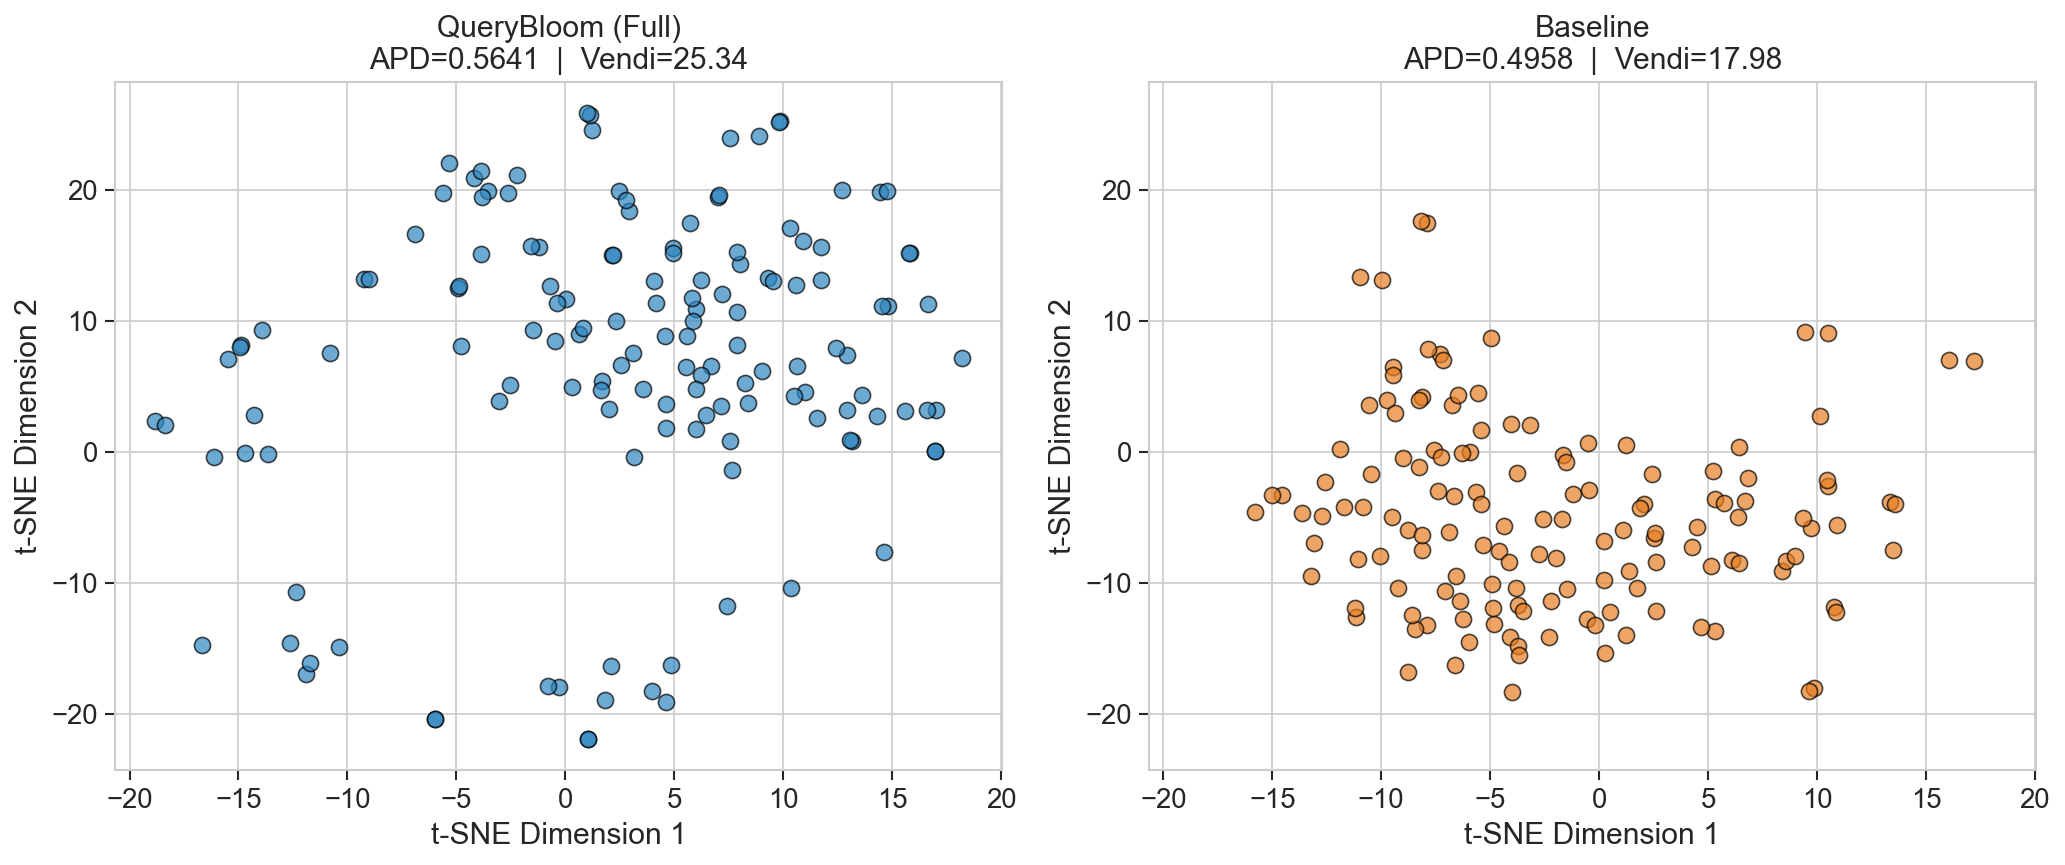

In [4]:
plot_semantic_embeddings(div1, div2, label1, label2)

## Figure 2 - Structural & Complexity Diversity

Three panels: (a) SPARQL feature distribution bars, (b) complexity-spread violins, (c) template / entity diversity scalars.

/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/querybloom/analyze/plots/diversity_plots.py:536: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


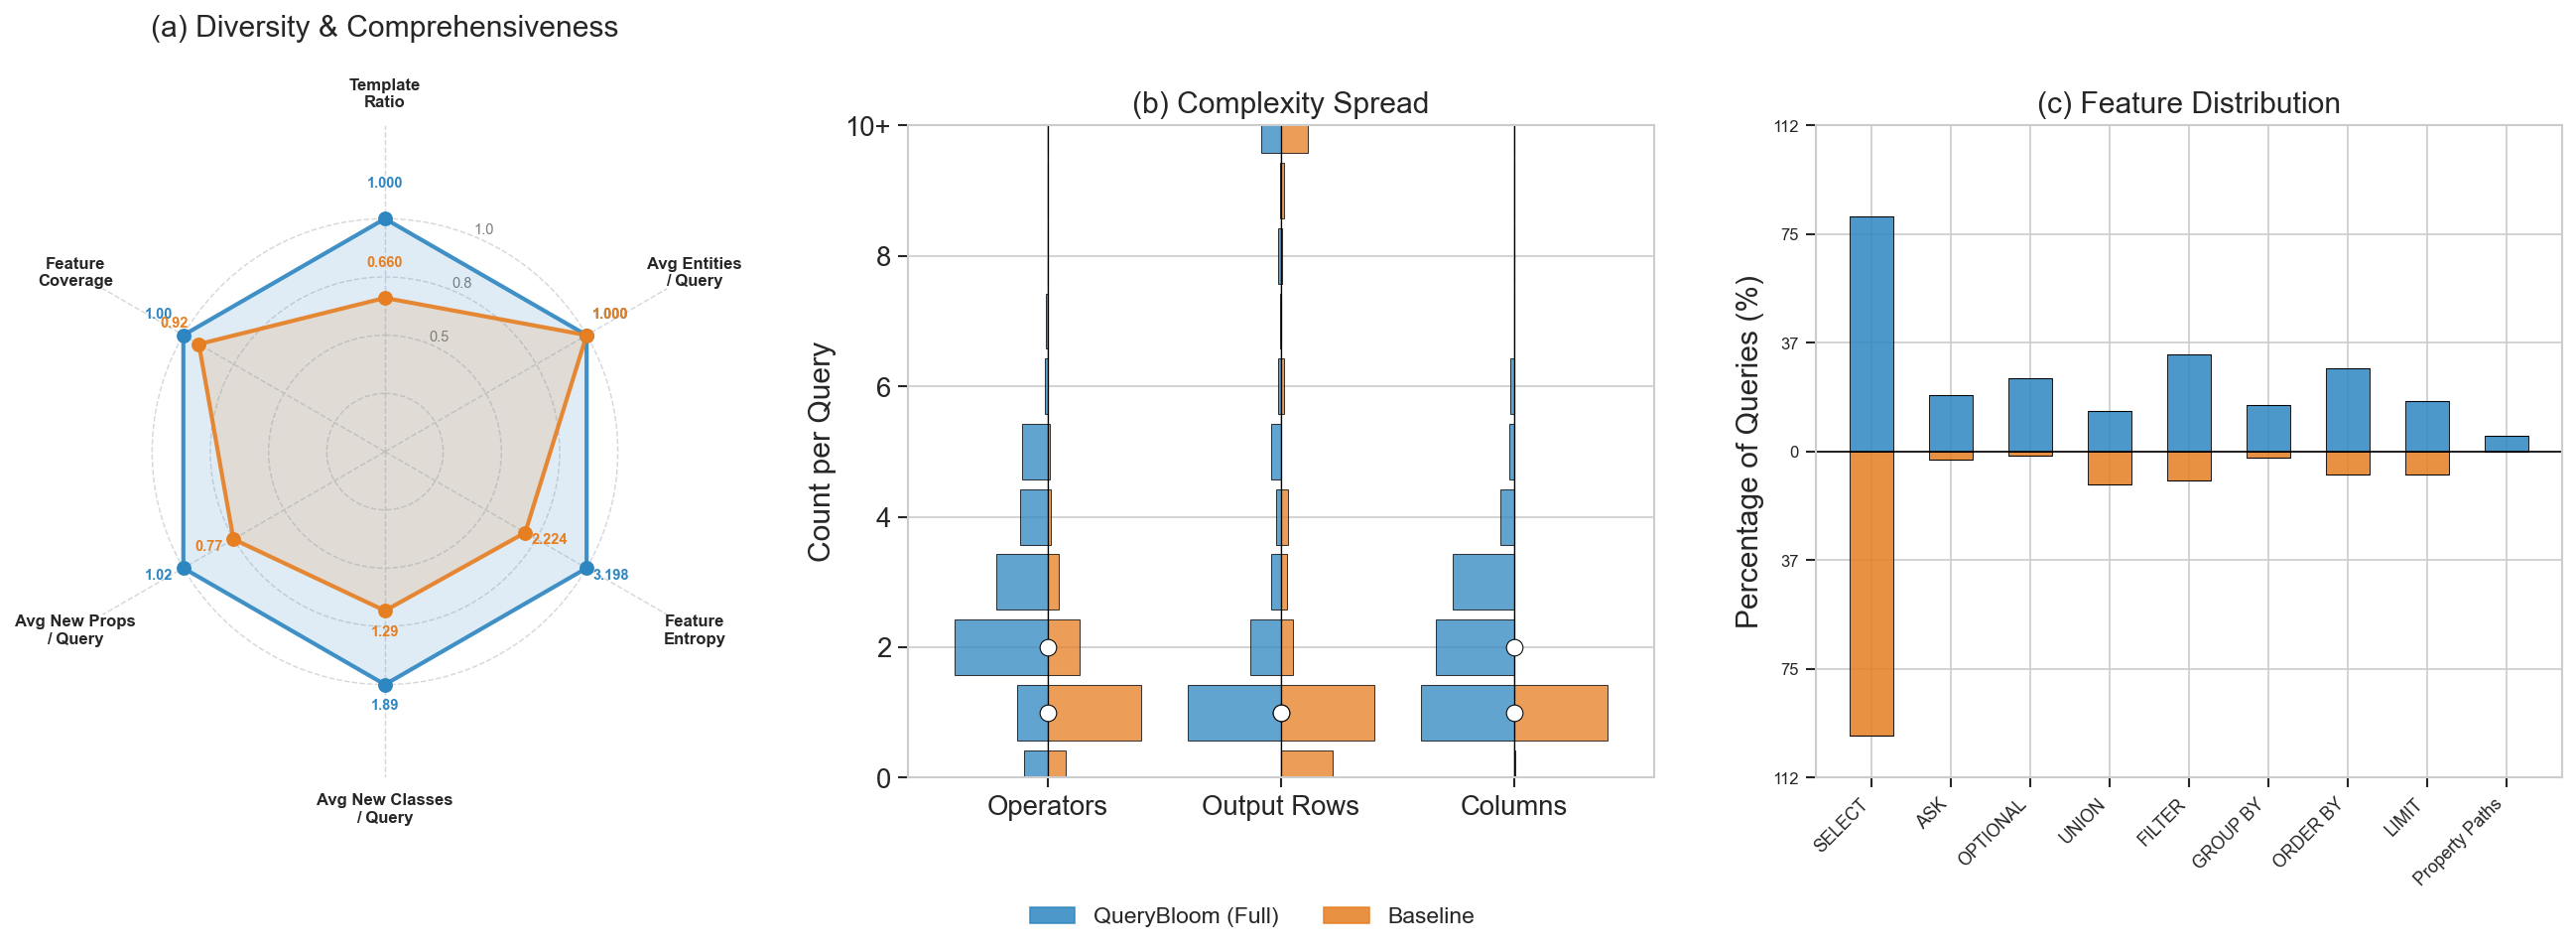

In [5]:
plot_structural_diversity(div1, div2, label1, label2, red1=red1, red2=red2, comp1=comp1, comp2=comp2, complexity_spread="histogram",show_redundancy_hatching=False)

## Figure 3b - Coverage Gaps Table

Random sample of classes and properties unique to one benchmark or missing from both.

http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.


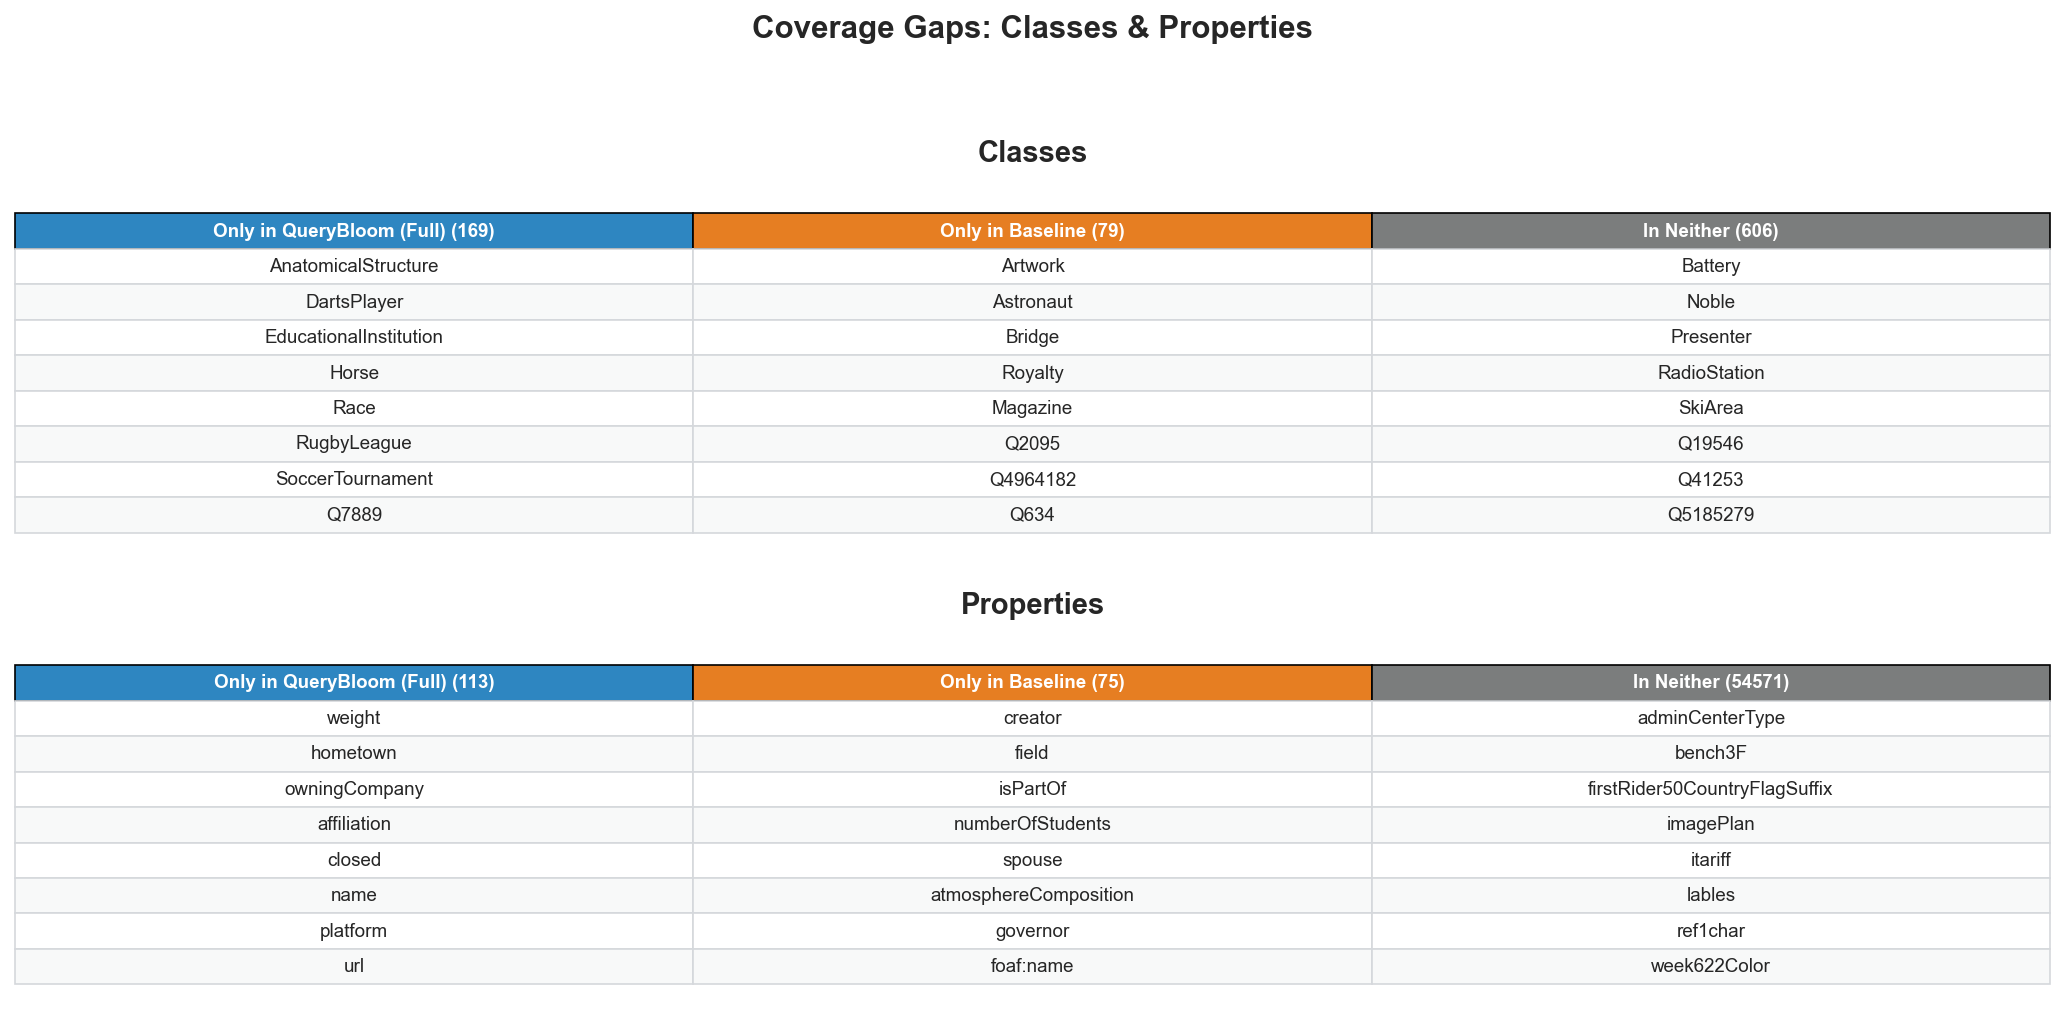

In [6]:
plot_coverage_table(queries1, queries2, kg_name, label1, label2, endpoint=endpoint)

## Entity Diversity Investigation

Break down `avg_entities_per_query` (distinct entities / number of queries) per benchmark:
- overall average and raw counts
- per-query entity distribution
- top-N most frequent entities in each benchmark
- shared vs exclusive entities

In [7]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from metrics.parsing import parse_and_extract_rdflib_metrics
from ontology_loader import load_ontology_classes
from plots.common import COLORS

onto_classes = load_ontology_classes(kg_name)

def collect_entities(queries, ep):
    per_query, all_mentions = [], []
    for query in queries:
        metrics = parse_and_extract_rdflib_metrics(query, endpoint=ep)
        entities = sorted({e for e in metrics["entities"] if e not in onto_classes})
        per_query.append(entities)
        all_mentions.extend(entities)
    return per_query, all_mentions

pq1, mentions1 = collect_entities(queries1, endpoint)
pq2, mentions2 = collect_entities(queries2, endpoint)

unique1, unique2 = set(mentions1), set(mentions2)
avg1 = len(unique1) / len(queries1) if queries1 else 0
avg2 = len(unique2) / len(queries2) if queries2 else 0

print(f"{'':30s}  {label1:>20s}  {label2:>20s}")
print(f"{'Queries':30s}  {len(queries1):>20d}  {len(queries2):>20d}")
print(f"{'Unique entities':30s}  {len(unique1):>20d}  {len(unique2):>20d}")
print(f"{'avg_entities_per_query':30s}  {avg1:>20.4f}  {avg2:>20.4f}")
shared = unique1 & unique2
print(f"\nShared entities: {len(shared)}")
print(f"Exclusive to {label1}: {len(unique1 - unique2)}")
print(f"Exclusive to {label2}: {len(unique2 - unique1)}")

http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Hurricanes_\(Super_Rugby\) does not look like a valid URI, trying to serialize this will break.


                                   QueryBloom (Full)              Baseline
Total entity mentions                            413                   167
Unique entities                                  219                   136
entity_diversity_ratio                        0.5303                0.8144

Shared entities: 6
Exclusive to QueryBloom (Full): 213
Exclusive to Baseline: 130


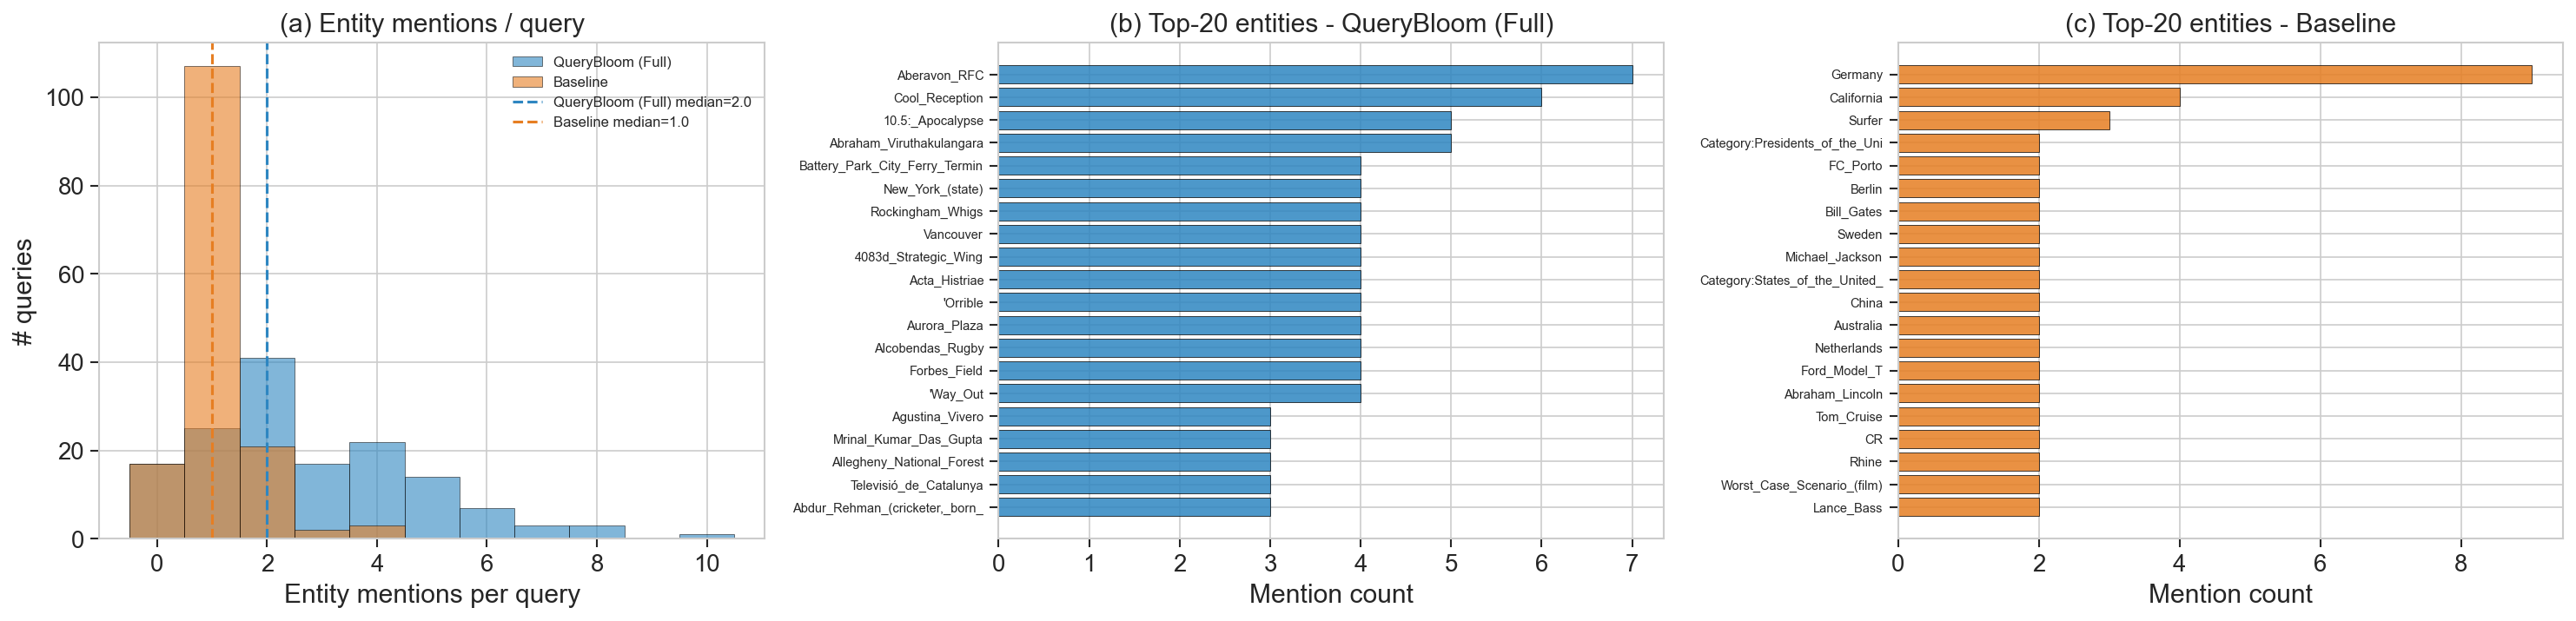

In [8]:
TOP_N = 20
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Per-query entity mention count distribution
ax = axes[0]
counts1 = [len(entities) for entities in pq1]
counts2 = [len(entities) for entities in pq2]
bins = np.arange(0, max(max(counts1, default=0), max(counts2, default=0)) + 2) - 0.5
ax.hist(counts1, bins=bins, alpha=0.6, color=COLORS[0], label=label1, edgecolor="k", linewidth=0.4)
ax.hist(counts2, bins=bins, alpha=0.6, color=COLORS[1], label=label2, edgecolor="k", linewidth=0.4)
ax.axvline(np.median(counts1), color=COLORS[0], linestyle="--", linewidth=1.5, label=f"{label1} median={np.median(counts1):.1f}")
ax.axvline(np.median(counts2), color=COLORS[1], linestyle="--", linewidth=1.5, label=f"{label2} median={np.median(counts2):.1f}")
ax.set_xlabel("Distinct entities per query")
ax.set_ylabel("# queries")
ax.set_title("(a) Distinct entities / query")
ax.legend(fontsize=8)

def short(uri):
    return uri.split("/")[-1].split("#")[-1][:30]

# Most frequent QueryBloom entities
ax = axes[1]
top1 = Counter(mentions1).most_common(TOP_N)
labels_b, vals_b = zip(*top1) if top1 else ([], [])
y = np.arange(len(labels_b))
ax.barh(y, vals_b, color=COLORS[0], alpha=0.85, edgecolor="k", linewidth=0.4)
ax.set_yticks(y)
ax.set_yticklabels([short(label) for label in labels_b], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Mention count")
ax.set_title(f"(b) Top-{TOP_N} entities - {label1}")

# Most frequent baseline entities
ax = axes[2]
top2 = Counter(mentions2).most_common(TOP_N)
labels_c, vals_c = zip(*top2) if top2 else ([], [])
y = np.arange(len(labels_c))
ax.barh(y, vals_c, color=COLORS[1], alpha=0.85, edgecolor="k", linewidth=0.4)
ax.set_yticks(y)
ax.set_yticklabels([short(label) for label in labels_c], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Mention count")
ax.set_title(f"(c) Top-{TOP_N} entities - {label2}")

plt.tight_layout()
plt.show()

## Redundancy Deep-Dive: NL Question vs. SPARQL Feature

For each feature where QueryBloom shows high redundancy (DISTINCT, FILTER, OPTIONAL, ORDER BY, LIMIT), show concrete examples so we can judge whether the natural language question itself implies the feature or whether it is a spurious SPARQL artifact.

In [9]:
show_redundancy_examples(queries1, questions1, query_endpoint)

Detecting redundant queries …
  Running / loading 243 unique queries …


NL Question,SPARQL Query
"Is Battery Park City Ferry Terminal—which opened in 1989 and is owned by the Port Authority of New York and New Jersey—located in Manhattan, New York State, or both?","PREFIX dbp: <http://dbpedia.org/property/> PREFIX dbr: <http://dbpedia.org/resource/> SELECT DISTINCT ?location WHERE { dbr:Battery_Park_City_Ferry_Terminal dbp:opened ?openingYear ; dbp:owned dbr:Port_Authority_of_New_York_and_New_Jersey . FILTER(STR(?openingYear) = ""1989"") { dbr:Battery_Park_City_Ferry_Terminal dbp:borough dbr:Manhattan . BIND(dbr:Manhattan AS ?location) } UNION { dbr:Battery_Park_City_Ferry_Terminal dbp:borough <http://dbpedia.org/resource/New_York_(state)> . BIND(<http://dbpedia.org/resource/New_York_(state)> AS ?location) } }"
"Were the birthplace and place of death of Abdur Rehman, the cricketer born in 1917, in different countries? If so, what were the two countries, and where did he die?","PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> SELECT DISTINCT ?birthCountry ?deathPlace ?deathCountry WHERE { <http://dbpedia.org/resource/Abdur_Rehman_(cricketer,_born_1917)> a dbo:Cricketer ; dbp:birthPlace ?birthPlace ; dbo:deathPlace ?deathPlace . ?birthPlace dbo:country ?birthCountry . ?deathPlace dbo:country ?deathCountry . FILTER(?birthCountry != ?deathCountry) }"
"What are Kerala’s recorded April rainfall and August high temperature, and which 10 places have the highest April rainfall among those with more April rainfall than Kerala, listed in descending order and with each place’s August high temperature included when available?",PREFIX dbp: <http://dbpedia.org/property/> PREFIX dbr: <http://dbpedia.org/resource/> PREFIX xsd: <http://www.w3.org/2001/XMLSchema#> SELECT DISTINCT ?keralaAprilRainfallMm ?keralaAugustHighC ?place ?placeAprilRainfallMm ?placeAugustHighC WHERE { dbr:Kerala dbp:aprRainMm ?keralaAprilRainfallMm ; dbp:augHighC ?keralaAugustHighC . ?place dbp:aprRainMm ?placeAprilRainfallMm . FILTER( xsd:decimal(?placeAprilRainfallMm) > xsd:decimal(?keralaAprilRainfallMm) ) OPTIONAL { ?place dbp:augHighC ?placeAugustHighC . } } ORDER BY DESC(xsd:decimal(?placeAprilRainfallMm)) LIMIT 10
"Among soccer clubs associated with the 2012 American soccer season, which has the largest whole-number value for highest attendance, and what is that value?","PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> PREFIX dbr: <http://dbpedia.org/resource/> PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> PREFIX xsd: <http://www.w3.org/2001/XMLSchema#> SELECT DISTINCT ?clubSeason ?highestAttendance WHERE { ?clubSeason rdf:type dbo:SoccerClub ; dbo:season dbr:2012_in_American_soccer ; dbp:highestAttendance ?highestAttendance . FILTER(REGEX(STR(?highestAttendance), ""^[0-9]+$"")) } ORDER BY DESC(xsd:integer(STR(?highestAttendance))) LIMIT 1"
"What is the longest Italian-language song performed by Patty Pravo, and what is its runtime in seconds?",PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbr: <http://dbpedia.org/resource/> SELECT DISTINCT ?song ?runtime WHERE { ?song a dbo:Song ; dbo:language dbr:Italian_language ; dbo:artist dbr:Patty_Pravo ; dbo:runtime ?runtime . { SELECT (MAX(?candidateRuntime) AS ?maximumRuntime) WHERE { ?candidateSong a dbo:Song ; dbo:language dbr:Italian_language ; dbo:artist dbr:Patty_Pravo ; dbo:runtime ?candidateRuntime . } } FILTER (?runtime = ?maximumRuntime) }
NL Question,SPARQL Query
"Who produced 10.5: Apocalypse, when was it released, which film preceded it, what country is that film from, and what was the show's opening theme, if known?",PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> SELECT DISTINCT ?producer ?releaseDate ?film ?country ?openingTheme WHERE { <http://dbpedia.org/resource/10.5:_Apocalypse> a dbo:TelevisionShow ; dbp:producer ?producer ; dbo:releaseDate ?releaseDate ; dbo:previousWork ?film . ?film a dbo:Film ; dbo:country ?country . ?country a dbo:Country . O

Done.
